# Does Analyst Text Help Predict the NFL Draft?

**Question.** NFL.com scouting reports have three parts: objective data (measurables, production and athleticism scores), a numeric **grade**, and a written **report**. Once you know the objective data and the grade, does the written report tell you anything more about where a prospect gets drafted?

**Workflow** (course template: data → cleaning → AI step → analysis → evaluation → decision)

| Stage | What happens | Notebook section |
|---|---|---|
| Data | 6,152 NFL.com Draft Tracker profiles, 2014–2026 (`scrape_nfl_prospects.py`) | 1 |
| Cleaning | Targets, split by year, text assembly, leakage checks | 1 |
| Baselines | Objective-only, + grade, TF-IDF text, combined | 3–6 |
| **AI step** | Claude Opus 5.5 extracts structured signals from **masked** reports. Checked against human labels (kappa) and for contamination | 7 |
| Analysis | Model with LLM features. Residuals by position, year, and school | 8–10 |
| Evaluation | Macro-F1 and weighted kappa with bootstrap CIs, paired deltas vs. minimum detectable difference, cost | 9, 11 |
| Decision | Governance thresholds for when to trust the text signal | 12 |

> **Status:** sections 0–6 (cleaning, summary statistics, baseline models), 7.1 (human labeling sample), and 9 (test-set comparison of the baselines) are complete. The LLM run (7.2+), Model E (8), and sections 10–12 are added after the LLM outputs are saved.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import cleaning as C
from src import evaluation as E
from src import modeling as M
from src import labeling as LB

SEED = 4340
ROOT = Path.cwd()
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)

# The LLM step (section 7) runs once and its outputs are saved to data/.
# Keep this True so re-running the notebook never calls the API (cost, time, and non-determinism).
USE_SAVED_LLM_OUTPUTS = True

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and clean

Each cleaning step is a small function in `src/cleaning.py`. We run them one at a time here so every step can be checked.

### 1.1 Raw data

In [2]:
raw = C.load_raw()
print(f"{len(raw):,} rows x {raw.shape[1]} columns, classes {raw.year.min()}-{raw.year.max()}")

# Unique key: two different players can share a name in the same class (e.g. Kevin White, WR and CB, 2015),
# so position is part of the key.
assert not raw.duplicated(C.KEY).any(), "duplicate (name, year, position)"
print("same name + year, different player:", raw.duplicated(["displayName", "year"]).sum())
raw.head(3).T

6,152 rows x 24 columns, classes 2014-2026
same name + year, different player: 4


,0,1,2
displayName,A.C. Leonard,AJ McCarron,Aaron Burks
position,TE,QB,WR
positionGroup,TE,QB,WR
collegeNames,Tennessee State,Alabama,Boise State
year,2014,2014,2014
draftRound,NaN,5.000,NaN
draftPick,NaN,24.000,NaN
draftOverallPick,NaN,164.000,NaN
draftTeam,NaN,Cincinnati Bengals,NaN
height,74.375,75.250,75.000


### 1.2 Analyst (author) cleanup

`detailAuthor` has typos ("Lance Zierlien", "Lance Zierlein.") and one value that isn't a name ("Round 7/PFA"). After cleanup, **Lance Zierlein wrote essentially every report from 2015 to 2026**, and Nolan Nawrocki wrote essentially all of 2014. Two other authors wrote one report each.

**Consequence:** we **cannot** compare accuracy between analysts. Analyst and year are fully confounded. So 2014 is kept out as a separate check, and the residual analysis looks at position, year, and school instead of analyst.

In [3]:
df = C.clean_authors(raw)
authors_by_year = pd.crosstab(df.year, df.detailAuthor.fillna("(none)"))
display(authors_by_year)

main_author = df.loc[df.year >= 2015, "detailAuthor"].value_counts(normalize=True)
assert main_author.index[0] == "Lance Zierlein" and main_author.iloc[0] > 0.98
a14 = df.loc[df.year == 2014, "detailAuthor"].value_counts(normalize=True)
assert a14.index[0] == "Nolan Nawrocki" and a14.iloc[0] > 0.99
# Two one-off reports by other authors (D. Jeremiah 2014, A. Gelhar 2018). Too few to matter; kept.
print(df[df.detailAuthor.isin(["Daniel Jeremiah", "Alex Gelhar"])][["displayName", "year", "detailAuthor"]])

detailAuthor,(none),Alex Gelhar,Daniel Jeremiah,Lance Zierlein,Nolan Nawrocki
year,,,,,
2014,82,0,1,0,387
2015,36,0,0,383,0
2016,11,0,0,403,0
2017,54,0,0,377,0
2018,167,1,0,476,0
2019,5,0,0,500,0
2020,0,0,0,506,0
2021,1,0,0,467,0
2022,2,0,0,464,0


        displayName  year     detailAuthor
403   Stephon Tuitt  2014  Daniel Jeremiah
1838     Chris Lacy  2018      Alex Gelhar


### 1.3 Positions

`positionGroup` (9 groups) is missing in 4 rows. We fill one from the raw position (Travis Hunter, WR/CB, goes to DB). The other 3 list no position at all, so they become `UNK` and are left out. Specialists (K/P/LS) are flagged and left out of the main analysis: no specialist was drafted in Round 1, and a kicker's report is scored on a different scale.

In [4]:
df = C.normalize_positions(df)
assert df.positionGroup.notna().all()
assert set(df.positionGroup) <= {"QB", "RB", "WR", "TE", "OL", "DL", "LB", "DB", "SPEC", "UNK"}
assert df.positionGroup.eq("UNK").sum() <= 3   # 3 profiles list no position at all -> excluded below
df.positionGroup.value_counts().to_frame("n").T

positionGroup,DB,DL,OL,WR,LB,RB,TE,QB,SPEC,UNK
n,1169,1095,1022,862,628,555,368,266,184,3


### 1.4 Grade cleanup

- One profile has `grade = 0` (Ricky Seals-Jones, 2017). That is a placeholder, not a grade, so it becomes missing.
- **The grade scale shifts across classes.** In later years the grades are bunched more tightly (see the table), so a raw 6.0 doesn't mean the same thing in 2016 as in 2025. Models use `grade_pct`, the prospect's percentile **within his own class**. The raw grade is kept for display.

In [5]:
print("grade <= 0 before cleaning:", (df.grade <= 0).sum())
df = C.clean_grade(df)
assert (df.grade.dropna() > 0).all()
assert df.grade_pct.dropna().between(0, 1).all()
df.groupby("year").grade.quantile([.25, .5, .75]).unstack().round(2).T

grade <= 0 before cleaning: 25


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
0.250,5.500,5.600,5.500,5.500,5.400,5.400,5.500,5.590,5.630,5.680,5.670,5.690,5.690
0.500,5.600,5.800,5.800,5.800,5.800,5.800,5.740,5.820,5.880,5.860,5.890,5.920,5.940
0.750,5.800,6.100,6.100,6.100,6.100,6.100,6.000,6.130,6.150,6.140,6.150,6.170,6.160


### 1.5 Targets: draft tiers

**Primary target: draft tier.**

| Tier | Rounds | NFL draft day |
|---|---|---|
| R1 | 1 | Day 1 |
| R2-3 | 2–3 | Day 2 |
| R4-7 | 4–7 | Day 3 |
| UDFA | not drafted | — |

**Why tiers instead of the exact pick:**
1. **They follow how the draft actually works.** The draft runs over three days, and analysts write the same way ("Day 2 starter", "late-round flier").
2. **Undrafted players stay in.** About 46% of prospects go undrafted, and they have no pick number. A pick-number model has to drop them, which biases the sample, or give them a made-up number like "pick 263".
3. **Exact late picks are mostly noise for this question.** Pick 150 vs. pick 180 depends on team needs and trades, not on the scouting report.
4. **It gives us the metrics the rubric asks for.** Precision, recall, F1, and quadratic-weighted kappa. Weighted kappa counts being one tier off as better than being three tiers off.
5. **It is a fairer task for the LLM.** "Which day of the draft?" can be answered from a report. "Which exact pick?" can't.
6. **Trade-off:** we lose detail within a tier, and R1 is only about 7% of rows. To cover this, we report macro-F1 and keep **log(pick) MAE on drafted players** as a secondary check.

In [6]:
df = C.add_targets(df)

d = df[df.drafted]
assert d.draftRound.between(1, 7).all()
assert d.draftOverallPick.dropna().between(1, 262).all()
assert df.loc[~df.drafted, ["draftOverallPick", "draftTeam"]].isna().all().all(), "undrafted row has a pick/team"
# tier must agree with round
expected = pd.cut(df.draftRound, [0, 1, 3, 7], labels=C.TIERS[:3]).astype(str).fillna("UDFA")
assert (expected == df.tier.astype(str)).all()

# 4 drafted players have a round but no overall pick: fine for tier, excluded from the log-pick check
print("drafted with round but no overall pick:", (df.drafted & df.draftOverallPick.isna()).sum())
df.tier.value_counts().reindex(C.TIERS).to_frame("n").assign(share=lambda t: t.n / t.n.sum()).T

drafted with round but no overall pick: 4


tier,R1,R2-3,R4-7,UDFA
n,414.000,912.000,2007.000,2819.000
share,0.067,0.148,0.326,0.458


### 1.6 School tier and analyst text

- `power5`: at least one listed school was a Power-5 program (or Notre Dame) during 2014–23. Transfers are listed as "School A/School B". This is used for the subgroup checks later.
- `scout_text`: the analyst's written evaluation, built as labeled **overview + strengths + weaknesses**.
- **Why `bio` is left out:**
  1. It is a factual career summary (high-school honors, games started, stats, all-conference teams), not the analyst's evaluation. Our question is about the *evaluation*, and `bio` is closer to the objective data in Model A.
  2. It isn't available consistently. In 2014–15 it is only a copy of `overview` (14% of the analysis set). It is empty in 7% of rows and patchy in the 2024–25 test classes.
  3. It is hard to anonymize. Mascots ("the Gators"), high schools, conferences, and coaches would let an LLM recognize the player.
- **Why `nflComparison` is left out:** it is missing in 66% of rows, and it names real NFL players, which is a contamination risk.

In [7]:
df = C.add_school_tier(df).pipe(C.build_text)

assert df.loc[df.has_text, "scout_text"].str.len().gt(30).all()
print(f"Power-5 share: {df.power5.mean():.1%}")
print(f"Rows with text: {df.has_text.mean():.1%}; median length {df.text_len.median():.0f} chars "
      f"(~{df.text_len.median() / 4:.0f} tokens)")
print("\nExample (truncated):\n", df.loc[df.has_text, "scout_text"].iloc[100][:600], "...")

Power-5 share: 72.0%
Rows with text: 94.7%; median length 1338 chars (~334 tokens)

Example (truncated):
 Overview: A physically talented receiving tight end, Lyerla was overshadowed by the play of emerging freshman Johnny Mundt and litany of issues (suspensions, drugs, academics). Has overcome a lot of adversity stemming back to his youth and defied the odds to become an impactful performer. Talent grades could garner interest in the second round, but past history could easily knock him down several rounds and off many draft boards. Would benefit tremendously from a coach willing to serve as a strong father figure.
Strengths: Good athlete. Fluid route runner. Very good body control. Adjusts easil ...


### 1.7 Leakage check: were reports edited after the draft?

Profiles are scraped *now*, so a report could have been updated to mention the team that drafted the player. That would leak the answer into the text.

**Test:** for drafted players, how often does the report name the team that **drafted him**, compared with how often it names a **random other team**? Reports do mention teams for comparisons (for example, "in the mold of Titans 2006 seventh-round pick..."), so the baseline isn't zero. Leakage would show up as the own-team rate being clearly higher than the random-team rate.

In [8]:
rng = np.random.default_rng(SEED)
dt = df[df.drafted & df.has_text & df.draftTeam.notna()].copy()
teams = np.array(sorted(C.NFL_TEAMS))
dt["random_team"] = [rng.choice(teams[teams != t]) for t in dt.draftTeam]
dt["mentions_own"] = [C.mentions_team(s, t) for s, t in zip(dt.scout_text, dt.draftTeam)]
dt["mentions_random"] = [C.mentions_team(s, t) for s, t in zip(dt.scout_text, dt.random_team)]

leak = dt[["mentions_own", "mentions_random"]].mean()
# bootstrap CI on the paired difference
idx = rng.integers(0, len(dt), size=(1000, len(dt)))
diff = dt.mentions_own.values[idx].mean(1) - dt.mentions_random.values[idx].mean(1)
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"names own drafting team: {leak.mentions_own:.2%}   names a random team: {leak.mentions_random:.2%}")
print(f"difference: {leak.mentions_own - leak.mentions_random:+.2%}  (95% CI {lo:+.2%} to {hi:+.2%})")

# Governance-style threshold: we treat >1 percentage point excess as evidence of post-draft editing.
LEAK_THRESHOLD = 0.01
assert leak.mentions_own - leak.mentions_random < LEAK_THRESHOLD, "possible post-draft edits; investigate"
dt.loc[dt.mentions_own, ["displayName", "year", "draftTeam"]].head()

names own drafting team: 0.12%   names a random team: 0.06%
difference: +0.06%  (95% CI -0.09% to +0.22%)


,displayName,year,draftTeam
3167,Julian Okwara,2020,Detroit Lions
4284,Treylon Burks,2022,Tennessee Titans
5757,Avieon Terrell,2026,Atlanta Falcons
6131,Uar Bernard,2026,Philadelphia Eagles


### 1.8 Split by year and the analysis set

We **split by year, never randomly**. A random split would let the model learn from a class's draft results and then be tested on players from that same class.

| Split | Classes | Purpose |
|---|---|---|
| train | 2015–2022 | fit models |
| val | 2023 | tune and choose models, refine prompts |
| test | 2024–2026 | final scoring, used once |
| holdout_nawrocki | 2014 | different analyst; checks whether results carry over |

**Analysis set** = has text **and** has grade **and** is not a specialist **and** has a known position. Every model is compared on the same rows.

In [9]:
df = C.assign_split(df).pipe(C.analysis_flags)
assert df.split.notna().all()

excl = pd.DataFrame({
    "no text": ~df.has_text,
    "no grade": ~df.has_grade,
    "specialist (K/P/LS)": df.is_spec,
    "no position": df.positionGroup.eq("UNK"),
})
excl_summary = pd.concat([
    excl.groupby(df.split).sum(),
    df.groupby("split").agg(total=("year", "size"), analysis_set=("in_analysis", "sum")),
], axis=1).loc[["train", "val", "test", "holdout_nawrocki"]]
display(excl_summary)
print("(exclusion reasons overlap; e.g. 2018 has ~165 stub profiles with neither text nor grade)")

A = df[df.in_analysis].copy()
assert A.has_text.all() and A.grade.notna().all() and not A.is_spec.any()
assert set(A.split) == {"train", "val", "test", "holdout_nawrocki"}
print(f"\nanalysis set: {len(A):,} prospects")

,no text,no grade,specialist (K/P/LS),no position,total,analysis_set
split,,,,,,
train,303,242,119,2,3853,3453
val,0,0,14,0,487,473
test,3,3,37,1,1342,1302
holdout_nawrocki,20,8,14,0,470,439


(exclusion reasons overlap; e.g. 2018 has ~165 stub profiles with neither text nor grade)

analysis set: 5,667 prospects


### 1.9 Save the cleaned data

In [10]:
df.to_parquet(C.CLEAN_PATH, index=False)
check = pd.read_parquet(C.CLEAN_PATH)
assert len(check) == len(df) and check.tier.cat.ordered
print("saved", C.CLEAN_PATH.relative_to(ROOT), check.shape)

saved data\prospects_clean.parquet (6152, 37)


## 2. Summary statistics

These cover the **analysis set** unless noted otherwise.

### 2.1 Size by split and tier

In [11]:
tab = pd.crosstab(A.split, A.tier, margins=True).loc[["train", "val", "test", "holdout_nawrocki", "All"]]
display(tab)
display((pd.crosstab(A.split, A.tier, normalize="index") * 100).round(1)
        .loc[["train", "val", "test", "holdout_nawrocki"]].rename(columns=lambda c: f"{c} %"))

tier,R1,R2-3,R4-7,UDFA,All
split,,,,,
train,255,560,1093,1545,3453
val,31,70,152,220,473
test,96,206,458,542,1302
holdout_nawrocki,32,68,142,197,439
All,414,904,1845,2504,5667


tier,R1 %,R2-3 %,R4-7 %,UDFA %
split,,,,
train,7.400,16.200,31.700,44.700
val,6.600,14.800,32.100,46.500
test,7.400,15.800,35.200,41.600
holdout_nawrocki,7.300,15.500,32.300,44.900


### 2.2 Numeric variables

In [12]:
num_cols = ["grade", "productionScore", "athleticismScore", "height", "weight", "armLength", "handSize", "text_len"]
desc = A[num_cols].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["missing %"] = 100 * (1 - desc["count"] / len(A))
display(desc)

display(A.groupby("tier", observed=True)[["grade", "productionScore", "athleticismScore", "text_len"]]
          .median().rename(columns=lambda c: f"median {c}"))

,count,mean,std,min,50%,max,missing %
grade,5667.000,5.867,0.376,4.900,5.830,7.500,0.000
productionScore,4070.000,68.364,10.357,50.000,67.265,99.000,28.181
athleticismScore,4071.000,70.833,10.967,51.000,70.780,99.000,28.163
height,5666.000,73.995,2.670,65.000,74.000,81.630,0.018
weight,5666.000,242.827,46.658,154.000,232.000,464.000,0.018
armLength,4084.000,32.278,1.434,27.625,32.250,36.875,27.934
handSize,4083.000,9.588,0.571,7.625,9.500,11.750,27.951
text_len,5667.000,1374.957,324.050,341.000,1350.000,4161.000,0.000


,median grade,median productionScore,median athleticismScore,median text_len
tier,,,,
R1,6.475,84.000,79.110,1758.000
R2-3,6.200,74.240,75.000,1516.500
R4-7,5.900,65.650,70.455,1363.000
UDFA,5.610,60.970,64.140,1246.500


The grade drops steadily from tier to tier, so it will be a strong predictor. That is exactly why we report every model **with and without** it: the grade is the analyst's own judgement, not objective data.

### 2.3 Draft outcome by position and school tier

In [13]:
by_pos = (A.groupby("positionGroup")
            .agg(n=("tier", "size"), drafted=("drafted", "mean"),
                 r1=("tier", lambda t: (t == "R1").mean()),
                 median_grade=("grade", "median"))
            .sort_values("drafted", ascending=False))
display(by_pos)
display(A.groupby("power5").agg(n=("tier", "size"), drafted=("drafted", "mean"),
                                r1=("tier", lambda t: (t == "R1").mean())))

,n,drafted,r1,median_grade
positionGroup,,,,
DL,1065,0.592,0.089,5.890
DB,1105,0.584,0.063,5.830
QB,252,0.579,0.167,5.800
OL,983,0.571,0.086,5.870
LB,576,0.556,0.057,5.800
TE,350,0.517,0.037,5.800
WR,807,0.511,0.072,5.830
RB,529,0.505,0.034,5.800


,n,drafted,r1
power5,,,
False,1519,0.404,0.020
True,4148,0.615,0.092


### 2.4 Figures

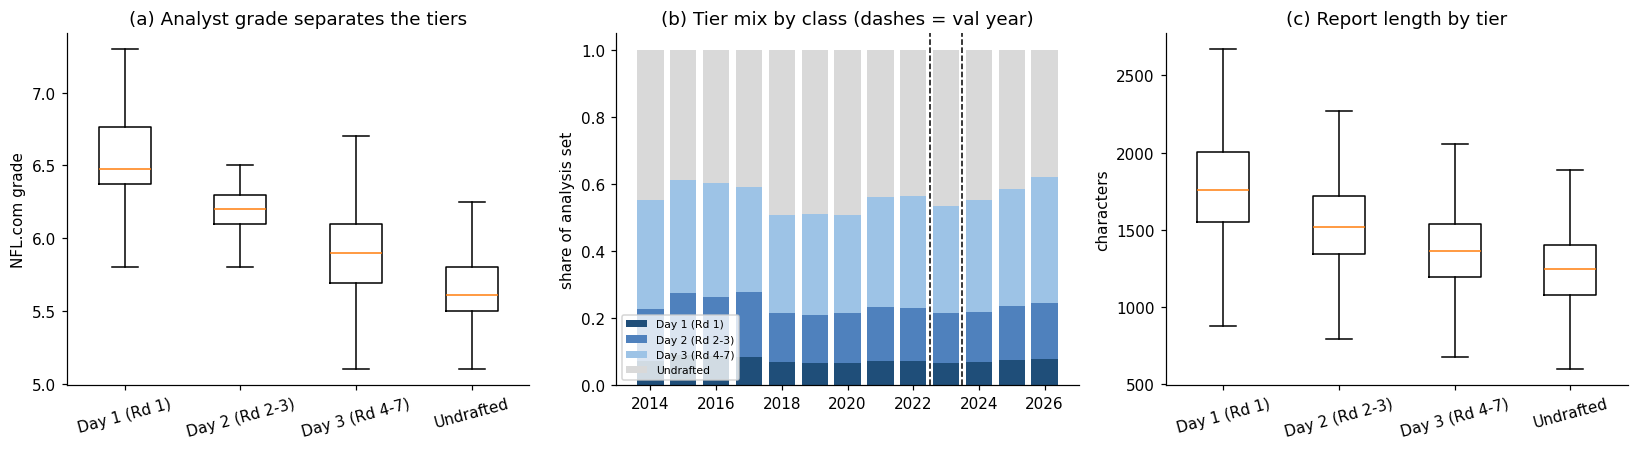

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) grade by tier
order = C.TIERS
axes[0].boxplot([A.loc[A.tier == t, "grade"] for t in order], showfliers=False)
axes[0].set_xticks(range(1, 5), [C.TIER_LABELS[t] for t in order], rotation=15)
axes[0].set_ylabel("NFL.com grade")
axes[0].set_title("(a) Analyst grade separates the tiers")

# (b) tier mix by year
mix = pd.crosstab(A.year, A.tier, normalize="index")[order]
bottom = np.zeros(len(mix))
for t, shade in zip(order, ["#1f4e79", "#4f81bd", "#9dc3e6", "#d9d9d9"]):
    axes[1].bar(mix.index, mix[t], bottom=bottom, color=shade, label=C.TIER_LABELS[t])
    bottom += mix[t].values
axes[1].axvline(2022.5, color="k", ls="--", lw=1); axes[1].axvline(2023.5, color="k", ls="--", lw=1)
axes[1].set_title("(b) Tier mix by class (dashes = val year)")
axes[1].set_ylabel("share of analysis set"); axes[1].legend(fontsize=7, loc="lower left")

# (c) text length by tier
axes[2].boxplot([A.loc[A.tier == t, "text_len"] for t in order], showfliers=False)
axes[2].set_xticks(range(1, 5), [C.TIER_LABELS[t] for t in order], rotation=15)
axes[2].set_ylabel("characters")
axes[2].set_title("(c) Report length by tier")
plt.tight_layout(); plt.show()

### 2.5 What we take into modeling

- **Class balance:** R1 is about 7–8% of the analysis set and UDFA about 40%. This is why we use macro-F1 and weighted kappa and not plain accuracy.
- **Missing data:** measurables and production/athleticism scores are missing for roughly a third of prospects. Section 3 handles this with missing-value indicators plus models that tolerate gaps, and it does not drop those rows.
- **Report length is itself a signal.** Median length rises from about 1,250 characters (UDFA) to about 1,760 (R1). The analyst writes more about prospects he rates higher. Any text model can pick this up without understanding the words, so section 5 adds a 'length-only' baseline to tell the content apart from the effort.
- **Grade scale drift:** models use the within-class `grade_pct` (section 1.4).
- **Leakage:** no sign that reports were edited after the draft (section 1.7). Still, the LLM will get **masked** text, because the model's own memory is a separate contamination risk (section 7).

## 3. Modeling setup and Model A

**Design: change only the information, never the model.** Every tier model is the same class-weighted multinomial logistic regression. The only thing that changes between models is what they get to see. So any difference between two models comes from the information, not from a different algorithm.

| Model | Sees | Answers |
|---|---|---|
| **A** | objective data: position, height, weight, arm, wingspan, hand, NGS production and athleticism scores, Power-5 | How far do numbers alone get you? |
| **B** | A + analyst grade (`grade_pct`) | What does the analyst's judgement add? |
| **C** | report text only (TF-IDF, words and two-word phrases) | How much is in the words by themselves? |
| **L** | report length only (characters per section, log) | Is the text signal just "he wrote more"? (see 2.5) |
| **D0** | A + text | Does text add **without** the grade? |
| **D** | B + text | **Main question:** does text add **beyond** objective data **and** the grade? |
| B+L | B + length | Is any gain from D just length? |

**Choices (and why):**
- **Logistic regression** is interpretable, fast, and stable on about 3,500 training rows. Gradient boosting is run as a robustness check in 6.3.
- **`class_weight="balanced"`** makes the model care about the small R1 class. Plain accuracy would reward predicting "UDFA" for everyone.
- **Masked text everywhere.** Names, schools, and teams are replaced before any text model sees the report. School names are *objective* information (Power-5 is already in A), so leaving them in would credit the text with something that isn't analysis. Claude gets the same masked input in section 7.
- **Stacking for D and D0.** The TF-IDF model's class probabilities become three extra columns. For training rows these are **out-of-fold** (one fold per class year). Otherwise the text score would have been fit on the same player's outcome, and D would look better than it is.
- **`draftGrade` is not used.** It is a site composite: R² = 0.91 from the production and athleticism scores alone, and it moves with the analyst grade. It would double-count A and B.
- **Tuning only on 2023 (val).** Each model's regularization strength `C` is picked by validation macro-F1. **The test classes (2024–26) are scored once, in section 9.**

### 3.1 Model inputs

In [15]:
A = M.add_model_columns(df[df.in_analysis])
S = {k: A[A.split == k].reset_index(drop=True) for k in ["train", "val", "test", "holdout_nawrocki"]}
train, val, test, hold = (S[k] for k in ["train", "val", "test", "holdout_nawrocki"])
print({k: len(v) for k, v in S.items()})

# Masking check: the full name must never survive.
left = sum(n in t for n, t in zip(A.displayName, A.text_masked))
print("reports where the full name survives masking:", left)
assert left == 0
print("\nmasked example:\n", A.text_masked.iloc[100][:500], "...")

{'train': 3453, 'val': 473, 'test': 1302, 'holdout_nawrocki': 439}
reports where the full name survives masking: 0

masked example:
 Overview: Strong-bodied, heavy-handed, short-area mauler who anchored one of the nation’s most physical, productive rushing attacks. Has athletic limitations, but compensates with strength, smarts and competitiveness. Has the makeup to overachieve, and could increase his value by proving versatile enough to back up at guard.
Strengths: Stout base. Works to re-anchor. Jolting punch. Strong upper body to latch onto and control defenders in short area. Generates movement in the run game. Understand ...


In [16]:
BEST_C = {}

def fit_tabular(name, C_reg, data, kind="logit", **kw):
    cols, pos = M.TABULAR_SPECS[name]
    return M.tabular_model(cols, C_reg, with_position=pos, kind=kind, **kw).fit(data, data.tier_code)

def tune_tabular(name, tr, va, grid=(0.01, 0.1, 1, 10)):
    rows = [{"C": c, **M.score_tiers(va.tier_code, fit_tabular(name, c, tr).predict(va))} for c in grid]
    t = pd.DataFrame(rows).set_index("C")
    BEST_C[name] = t.macro_f1.idxmax()
    return t

def confusion(y, yhat):
    return pd.crosstab(pd.Series(np.asarray(y)).map(dict(enumerate(C.TIERS))).rename("actual"),
                       pd.Series(np.asarray(yhat)).map(dict(enumerate(C.TIERS))).rename("predicted")
                       ).reindex(index=C.TIERS, columns=C.TIERS, fill_value=0)

pred_val = {}

### 3.2 Model A: objective data only

In [17]:
display(tune_tabular("A", train, val))
mA = fit_tabular("A", BEST_C["A"], train)
pred_val["A"] = mA.predict(val)
print("chosen C:", BEST_C["A"])
display(confusion(val.tier_code, pred_val["A"]))

,macro_f1,qwk,accuracy,within_1_tier
C,,,,
0.010,0.507,0.712,0.575,0.958
0.100,0.538,0.717,0.594,0.960
1.000,0.536,0.719,0.592,0.962
10.000,0.527,0.707,0.588,0.956


chosen C: 0.1


predicted,R1,R2-3,R4-7,UDFA
actual,,,,
R1,20,11,0,0
R2-3,18,31,17,4
R4-7,6,40,65,41
UDFA,0,9,46,165


**Missing scores are a signal.** NGS production and athleticism scores exist for nearly every R1 player but for only about half of UDFA players (see below). Missing scores most likely mean the player didn't test at the combine or a big pro day. That is **pre-draft** information, so it's fair to use, and the missing-value indicators let the model use it.

**Caveat:** if NFL.com filled in scores *after* the draft, and only for drafted players, this would be leakage. We can't check that from the data. So we refit A **without** the indicators, to show how much of A depends on it.

In [18]:
display(A.groupby("tier", observed=True).productionScore.apply(lambda s: s.notna().mean())
          .to_frame("share with NGS scores").T)
mA_noind = fit_tabular("A", BEST_C["A"], train, indicators=False)
print("val, A with missing indicators   :", {k: round(v, 3) for k, v in M.score_tiers(val.tier_code, pred_val["A"]).items()})
print("val, A without missing indicators:", {k: round(v, 3) for k, v in M.score_tiers(val.tier_code, mA_noind.predict(val)).items()})

tier,R1,R2-3,R4-7,UDFA
share with NGS scores,0.998,0.988,0.850,0.477


val, A with missing indicators   : {'macro_f1': 0.538, 'qwk': 0.717, 'accuracy': 0.594, 'within_1_tier': 0.96}
val, A without missing indicators: {'macro_f1': 0.481, 'qwk': 0.667, 'accuracy': 0.503, 'within_1_tier': 0.964}


## 4. Model B: objective data + analyst grade

In [19]:
display(tune_tabular("B", train, val))
pred_val["B"] = fit_tabular("B", BEST_C["B"], train).predict(val)
print("chosen C:", BEST_C["B"])
display(confusion(val.tier_code, pred_val["B"]))

,macro_f1,qwk,accuracy,within_1_tier
C,,,,
0.010,0.556,0.751,0.622,0.970
0.100,0.587,0.775,0.643,0.979
1.000,0.596,0.784,0.647,0.985
10.000,0.600,0.784,0.651,0.983


chosen C: 10.0


predicted,R1,R2-3,R4-7,UDFA
actual,,,,
R1,24,7,0,0
R2-3,21,32,16,1
R4-7,4,31,83,34
UDFA,0,3,48,169


## 5. Model C: text only, and Model L: length only

### 5.1 TF-IDF text model

In [20]:
rows = []
for c in (0.1, 0.3, 1, 3):
    m = M.text_model(c).fit(train.text_masked, train.tier_code)
    rows.append({"C": c, **M.score_tiers(val.tier_code, m.predict(val.text_masked))})
tC = pd.DataFrame(rows).set_index("C"); BEST_C["C"] = tC.macro_f1.idxmax()
display(tC); print("chosen C:", BEST_C["C"])

mC = M.text_model(BEST_C["C"]).fit(train.text_masked, train.tier_code)
pred_val["C"] = mC.predict(val.text_masked)

,macro_f1,qwk,accuracy,within_1_tier
C,,,,
0.100,0.444,0.542,0.548,0.886
0.300,0.461,0.548,0.552,0.899
1.000,0.448,0.536,0.556,0.911
3.000,0.415,0.473,0.535,0.903


chosen C: 0.3


**What words does the text model use?** These are the highest-weight terms for R1 and for UDFA. If they are mostly about effort ("captain", "motor") or projection ("backup", "developmental"), the text carries the analyst's **judgement**, and that judgement is also what the grade summarizes.

In [21]:
vocab = np.array(mC.named_steps["tfidf"].get_feature_names_out())
coef = mC.named_steps["clf"].coef_
top = pd.DataFrame({f"top {t}": vocab[np.argsort(coef[k])[::-1][:20]] for k, t in [(0, "R1"), (3, "UDFA")]})
top.index += 1
display(top.T)

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
top R1,elite,rare,talent,times,all,should,instant,quick,him to,snap,talented,dominant,of the,release,any,early,high,explosive,field,pocket
top UDFA,roster,enough,below,below average,camp,shot,unable to,unable,lacks,lacks the,squad,decent,pro day,practice squad,poor,doesn have,adequate,practice,free agent,agent


### 5.2 Length-only baseline

In [22]:
display(tune_tabular("L", train, val))
pred_val["L"] = fit_tabular("L", BEST_C["L"], train).predict(val)

,macro_f1,qwk,accuracy,within_1_tier
C,,,,
0.010,0.270,0.258,0.482,0.837
0.100,0.359,0.347,0.518,0.863
1.000,0.371,0.352,0.520,0.863
10.000,0.354,0.348,0.514,0.863


## 6. Model D: objective data + grade + text

### 6.1 Stacked text score

In [23]:
P = M.text_probabilities(train, {"val": val, "test": test, "holdout": hold}, BEST_C["C"])
trainP, valP, testP, holdP = (M.attach_text_probs(d, P[k]) for d, k in
                              [(train, "train"), (val, "val"), (test, "test"), (hold, "holdout")])

# Sanity check: out-of-fold text scores on train should perform about like the text model on val, not better.
oof = M.score_tiers(train.tier_code, P["train"].argmax(1))["macro_f1"]
print(f"text model macro-F1  out-of-fold train: {oof:.3f}   val: {M.score_tiers(val.tier_code, P['val'].argmax(1))['macro_f1']:.3f}")
assert oof < 0.6, "OOF text score looks leaky"

for name in ["D0", "D", "B+L"]:
    print(name); display(tune_tabular(name, trainP, valP))
    pred_val[name] = fit_tabular(name, BEST_C[name], trainP).predict(valP)

text model macro-F1  out-of-fold train: 0.429   val: 0.461
D0


,macro_f1,qwk,accuracy,within_1_tier
C,,,,
0.010,0.559,0.739,0.615,0.966
0.100,0.554,0.733,0.613,0.966
1.000,0.542,0.728,0.611,0.966
10.000,0.542,0.730,0.613,0.966


D


,macro_f1,qwk,accuracy,within_1_tier
C,,,,
0.010,0.578,0.753,0.626,0.973
0.100,0.587,0.764,0.634,0.979
1.000,0.596,0.772,0.641,0.981
10.000,0.594,0.769,0.641,0.979


B+L


,macro_f1,qwk,accuracy,within_1_tier
C,,,,
0.010,0.604,0.761,0.649,0.983
0.100,0.608,0.775,0.653,0.987
1.000,0.608,0.784,0.649,0.989
10.000,0.613,0.786,0.653,0.989


### 6.2 Validation summary (2023)

In [24]:
ORDER = ["L", "C", "A", "D0", "B", "B+L", "D"]
val_table = pd.DataFrame({M.MODEL_LABELS[k]: M.score_tiers(val.tier_code, pred_val[k]) for k in ORDER}).T
val_table["C (reg.)"] = [BEST_C[k] for k in ORDER]
display(val_table)

,macro_f1,qwk,accuracy,within_1_tier,C (reg.)
L: report length only,0.371,0.352,0.520,0.863,1.000
C: text only (TF-IDF),0.461,0.548,0.552,0.899,0.300
A: objective,0.538,0.717,0.594,0.960,0.100
D0: objective + text,0.559,0.739,0.615,0.966,0.010
B: objective + grade,0.600,0.784,0.651,0.983,10.000
B+L: objective + grade + length,0.613,0.786,0.653,0.989,10.000
D: objective + grade + text,0.596,0.772,0.641,0.981,1.000


### 6.3 Robustness: gradient boosting instead of logistic regression

If text only helped inside a flexible non-linear model, gradient boosting would show it.

In [25]:
rob = {}
for name in ["A", "B", "D"]:
    g = fit_tabular(name, None, trainP, kind="gbm")
    rob[name] = {"logit macro-F1": M.score_tiers(valP.tier_code, pred_val[name])["macro_f1"],
                 "boosting macro-F1": M.score_tiers(valP.tier_code, g.predict(valP))["macro_f1"]}
display(pd.DataFrame(rob).T.rename(index=M.MODEL_LABELS))

,logit macro-F1,boosting macro-F1
A: objective,0.538,0.525
B: objective + grade,0.600,0.561
D: objective + grade + text,0.596,0.582


### 6.4 Minimum detectable difference and the decision rule (set **before** scoring test)

**Course MDD** (Week 8, Class 14): mean + 1 SD of the absolute disagreement between two "raters" scoring the same thing. Draft outcomes have no rater noise, so the noise that matters here is **training noise**: refit the *same* model (B) on 20 bootstrap resamples of the training classes, score each refit on 2023, and take the pairwise gaps between refits. A model gap smaller than that is no bigger than what you get from refitting the same model.

The human-labeling MDD (partner vs. partner) is added in section 7 for the LLM outputs.

**Decision rule (pre-registered):** text "adds value" on the test classes only if **both**
1. the 95% paired-bootstrap CI for Δ (D − B, or D0 − A) is above 0, **and**
2. Δ is larger than the MDD.

If the CI includes 0, we report "no detectable difference", not "text is useless".

In [26]:
rng = np.random.default_rng(SEED)
refits = []
for b in range(20):
    boot = trainP.iloc[rng.integers(0, len(trainP), len(trainP))]
    refits.append(M.score_tiers(valP.tier_code, fit_tabular("B", BEST_C["B"], boot).predict(valP)))
refits = pd.DataFrame(refits)
MDD = {k: E.mdd(E.pairwise_diffs(refits[[k]].T)) for k in ["macro_f1", "qwk"]}
display(refits[["macro_f1", "qwk"]].describe().loc[["mean", "std", "min", "max"]])
print("MDD (mean + 1 SD of pairwise |refit gap|):", {k: round(v, 4) for k, v in MDD.items()})

,macro_f1,qwk
mean,0.591,0.771
std,0.015,0.008
min,0.568,0.750
max,0.620,0.786


MDD (mean + 1 SD of pairwise |refit gap|): {'macro_f1': 0.0289, 'qwk': 0.0157}


## 7. AI step: LLM on the scouting text

### 7.1 Human labeling sample (codebook: `docs/codebook.md`)

Both partners label the same reports by hand, following the Week 7 (Class 12) method. Later, Claude labels the same items. The labels give us:
- **human–human kappa** (the human ceiling) and the human **MDD**,
- **LLM–human kappa** for each field (used for the keep/drop governance rule),
- a "human reading the text" benchmark to compare with model C and with Claude.

**Sample:** 20 **practice** items from 2023 (5 per tier), used to refine the codebook and not scored, plus 100 **evaluation** items from 2024–26 (25 per tier). The sample is stratified so R1 has enough items for per-class agreement; uniform sampling would give only about 8. The order is shuffled. Workbooks show only position and masked text, and they are never overwritten once created.

In [27]:
items = LB.draw_label_sample(A, seed=SEED)
assert items.groupby("set").size().to_dict() == {"eval": 100, "practice": 20}
assert not any(n in t for n, t in zip(items.displayName, items.text_masked))

key = items[["item_id", "set", *C.KEY]]
LB.LABEL_DIR.mkdir(parents=True, exist_ok=True)
if LB.KEY_PATH.exists():   # the sample must be identical on every run
    pd.testing.assert_frame_equal(pd.read_csv(LB.KEY_PATH), key, check_dtype=False)
    print("label key matches saved key")
else:
    key.to_csv(LB.KEY_PATH, index=False); print("wrote", LB.KEY_PATH.relative_to(ROOT))

for who in LB.LABELERS:
    p = LB.workbook_path(who)
    if p.exists():
        print(f"{p.relative_to(ROOT)} exists; kept (never overwritten)")
    else:
        LB.write_workbook(items, p, who); print("wrote", p.relative_to(ROOT))

display(pd.crosstab(items.set, items.positionGroup, margins=True))

label key matches saved key
data\labels\labels_partner1.xlsx exists; kept (never overwritten)
data\labels\labels_partner2.xlsx exists; kept (never overwritten)


positionGroup,DB,DL,LB,OL,QB,RB,TE,WR,All
set,,,,,,,,,
eval,17,23,2,25,5,7,9,12,100
practice,6,5,0,6,0,1,0,2,20
All,23,28,2,31,5,8,9,14,120


> **7.2–7.7** (prompt and pilot, full masked run, human agreement and kappa, contamination check, self-consistency, saved outputs) and **8. Model E** are added once labels and LLM outputs exist.

## 9. Test-set comparison (2024–26 classes)

Every model is refit on the training classes with its chosen `C` and scored **once** on the test classes. 95% CIs come from 1,000 bootstrap resamples of test prospects. Deltas use **paired** resamples (the same prospects for both models). Model E joins this table after section 8.

### 9.1 Tier models

In [28]:
pred_test, pred_hold = {}, {}
for name in ["A", "B", "L", "B+L", "D0", "D"]:
    m = fit_tabular(name, BEST_C[name], trainP)
    pred_test[name], pred_hold[name] = m.predict(testP), m.predict(holdP)
pred_test["C"], pred_hold["C"] = P["test"].argmax(1), P["holdout"].argmax(1)

y_test = testP.tier_code.values
rows = []
for name in ORDER:
    f1 = E.bootstrap_ci(E.macro_f1, y_test, pred_test[name], seed=SEED)
    q = E.bootstrap_ci(E.qwk, y_test, pred_test[name], seed=SEED)
    s = M.score_tiers(y_test, pred_test[name])
    rows.append({"model": M.MODEL_LABELS[name], "macro-F1": f1["estimate"],
                 "F1 95% CI": f"{f1['ci_low']:.3f} to {f1['ci_high']:.3f}",
                 "QWK": q["estimate"], "QWK 95% CI": f"{q['ci_low']:.3f} to {q['ci_high']:.3f}",
                 "accuracy": s["accuracy"], "within 1 tier": s["within_1_tier"]})
results_test = pd.DataFrame(rows).set_index("model")
display(results_test)
print(f"n = {len(y_test):,} test prospects")

display(pd.DataFrame({M.MODEL_LABELS[k]: M.per_class_recall(y_test, pred_test[k]) for k in ORDER}).T
          .rename(columns=lambda c: f"recall {c}"))

,macro-F1,F1 95% CI,QWK,QWK 95% CI,accuracy,within 1 tier
model,,,,,,
L: report length only,0.395,0.359 to 0.426,0.482,0.431 to 0.528,0.492,0.879
C: text only (TF-IDF),0.448,0.417 to 0.479,0.544,0.495 to 0.588,0.508,0.902
A: objective,0.578,0.546 to 0.610,0.700,0.670 to 0.730,0.593,0.959
D0: objective + text,0.603,0.573 to 0.631,0.730,0.702 to 0.757,0.617,0.970
B: objective + grade,0.662,0.633 to 0.691,0.788,0.764 to 0.811,0.657,0.986
B+L: objective + grade + length,0.677,0.648 to 0.705,0.791,0.766 to 0.813,0.666,0.988
D: objective + grade + text,0.662,0.634 to 0.691,0.784,0.759 to 0.808,0.654,0.985


n = 1,302 test prospects


,recall R1,recall R2-3,recall R4-7,recall UDFA
L: report length only,0.396,0.214,0.079,0.963
C: text only (TF-IDF),0.438,0.345,0.249,0.801
A: objective,0.594,0.631,0.480,0.673
D0: objective + text,0.656,0.558,0.546,0.692
B: objective + grade,0.844,0.641,0.541,0.729
B+L: objective + grade + length,0.802,0.689,0.552,0.729
D: objective + grade + text,0.854,0.641,0.535,0.723


### 9.2 Does each information source add? (paired deltas vs. MDD)

In [29]:
COMPARISONS = [("A", "B", "grade beyond objective"),
               ("B", "D", "text beyond objective + grade (main question)"),
               ("A", "D0", "text beyond objective (no grade)"),
               ("L", "C", "text content beyond length"),
               ("B", "B+L", "length beyond objective + grade")]
METRICS = {"macro_f1": E.macro_f1, "qwk": E.qwk}

def verdict(d, mdd):
    if d["ci_low"] > 0 and d["delta"] > mdd: return "adds (CI > 0 and > MDD)"
    if d["ci_low"] > 0:                       return "real but below MDD"
    if d["ci_high"] < 0:                      return "worse"
    return "no detectable difference"

rows = []
for a, b, what in COMPARISONS:
    for mname, f in METRICS.items():
        d = E.paired_bootstrap_delta(f, y_test, pred_test[a], pred_test[b], seed=SEED)
        rows.append({"comparison": f"{b} − {a}", "question": what, "metric": mname, **d,
                     "MDD": MDD[mname], "verdict": verdict(d, MDD[mname])})
deltas = pd.DataFrame(rows)
display(deltas.set_index(["comparison", "question", "metric"]))

delta  ci_low  ci_high   MDD                   verdict
comparison question                                      metric                                                          
B − A      grade beyond objective                        macro_f1  0.084   0.053    0.113 0.029   adds (CI > 0 and > MDD)
                                                         qwk       0.088   0.069    0.109 0.016   adds (CI > 0 and > MDD)
D − B      text beyond objective + grade (main question) macro_f1 -0.000  -0.011    0.012 0.029  no detectable difference
                                                         qwk      -0.004  -0.010    0.004 0.016  no detectable difference
D0 − A     text beyond objective (no grade)              macro_f1  0.025  -0.002    0.051 0.029  no detectable difference
                                                         qwk       0.030   0.014    0.049 0.016   adds (CI > 0 and > MDD)
C − L      text content beyond length                    macro_f1  0.053   0.015    0.094 0.029   adds (CI > 0 and > MDD)
                                                         qwk       0.062   0.016    0.107 0.016   adds (CI > 0 and > MDD)
B+L − B    length beyond objective + grade               macro_f1  0.015   0.003    0.029 0.029        real but below MDD
                                                         qwk       0.003  -0.003    0.009 0.016  no detectable difference

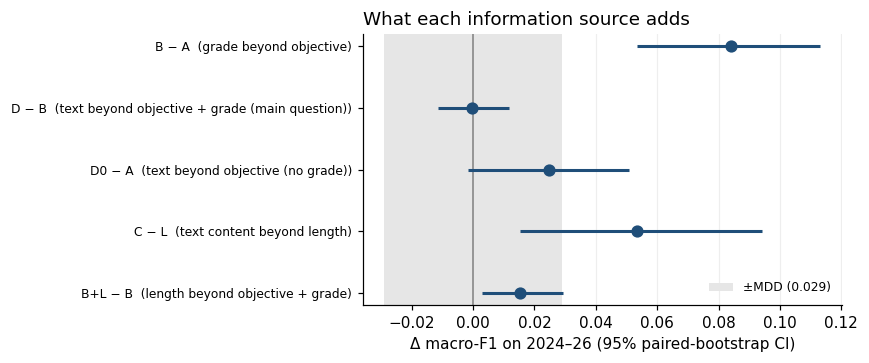

In [30]:
# Figure: paired deltas in macro-F1 with 95% CIs; shaded band = MDD (smaller gaps are within training noise)
f1d = deltas[deltas.metric == "macro_f1"].iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axvspan(-MDD["macro_f1"], MDD["macro_f1"], color="#e6e6e6", lw=0, label=f"±MDD ({MDD['macro_f1']:.3f})")
ax.axvline(0, color="#7f7f7f", lw=1)
yy = np.arange(len(f1d))
ax.hlines(yy, f1d.ci_low, f1d.ci_high, color="#1f4e79", lw=2)
ax.plot(f1d.delta, yy, "o", color="#1f4e79", ms=7)
ax.set_yticks(yy, [f"{c}  ({q})" for c, q in zip(f1d.comparison, f1d.question)], fontsize=8)
ax.set_xlabel("Δ macro-F1 on 2024–26 (95% paired-bootstrap CI)")
ax.set_title("What each information source adds", loc="left")
ax.grid(axis="x", color="#eeeeee"); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

### 9.3 Secondary check: pick number for drafted players

Ridge regression on log(overall pick), using drafted players only, with the same feature sets. Error is in **picks** (MAE). Lower is better.

In [31]:
dtr = trainP[trainP.drafted & trainP.log_pick.notna()]
dte = testP[testP.drafted & testP.log_pick.notna()]
pick_pred = {}
for name in ["A", "B", "D0", "D"]:
    cols, _ = M.TABULAR_SPECS[name]
    pick_pred[name] = M.pick_model(cols).fit(dtr, dtr.log_pick).predict(dte)
pick_pred["C"] = M.text_pick_model().fit(dtr.text_masked, dtr.log_pick).predict(dte.text_masked)

yl = dte.log_pick.values
pick_tab = pd.DataFrame({M.MODEL_LABELS[k]: E.bootstrap_ci(M.pick_mae, yl, pick_pred[k], seed=SEED)
                         for k in ["C", "A", "D0", "B", "D"]}).T
pick_tab.columns = ["MAE (picks)", "CI low", "CI high", "n"]
display(pick_tab)
for a, b in [("B", "D"), ("A", "D0")]:
    d = E.paired_bootstrap_delta(M.pick_mae, yl, pick_pred[a], pick_pred[b], seed=SEED)
    print(f"{b} − {a}: {d['delta']:+.1f} picks (95% CI {d['ci_low']:+.1f} to {d['ci_high']:+.1f}; negative = text helps)")

,MAE (picks),CI low,CI high,n
C: text only (TF-IDF),58.266,55.338,60.982,760.000
A: objective,49.304,46.492,52.104,760.000
D0: objective + text,46.033,43.252,48.682,760.000
B: objective + grade,45.314,42.671,47.860,760.000
D: objective + grade + text,44.230,41.527,46.936,760.000


D − B: -1.1 picks (95% CI -2.0 to -0.2; negative = text helps)
D0 − A: -3.3 picks (95% CI -4.7 to -1.8; negative = text helps)


### 9.4 Different analyst: 2014 (Nolan Nawrocki)

All models were trained on Zierlein's reports. Scoring them on 2014 shows whether what they learned is specific to one writer's vocabulary.

In [32]:
yh = holdP.tier_code.values
display(pd.DataFrame({M.MODEL_LABELS[k]: M.score_tiers(yh, pred_hold[k]) for k in ["C", "A", "B", "D"]}).T)
d = E.paired_bootstrap_delta(E.macro_f1, yh, pred_hold["B"], pred_hold["D"], seed=SEED)
print(f"2014: D − B macro-F1 {d['delta']:+.3f} (95% CI {d['ci_low']:+.3f} to {d['ci_high']:+.3f}); n = {len(yh)}")

,macro_f1,qwk,accuracy,within_1_tier
C: text only (TF-IDF),0.413,0.372,0.497,0.866
A: objective,0.585,0.742,0.613,0.977
B: objective + grade,0.612,0.745,0.624,0.979
D: objective + grade + text,0.617,0.744,0.624,0.982


2014: D − B macro-F1 +0.005 (95% CI -0.018 to +0.029); n = 439


### 9.5 What the baselines say

Numbers are from the run above, on 1,302 test prospects (2024–26 classes).

1. **The grade is the big step.** Objective data alone (A) gets macro-F1 0.578. Adding the analyst grade (B) gives 0.662 (+0.084, 95% CI +0.053 to +0.113, about 3× the MDD). Most of the gain is in R1 recall (0.59 → 0.84).
2. **Main question: once the grade is in, the text adds nothing we can detect.** D − B = −0.000 macro-F1 (CI −0.011 to +0.012) and −0.004 QWK. Both CIs sit inside ±MDD. The same holds on the 2014 Nawrocki class (+0.005, CI −0.018 to +0.029) and with gradient boosting (6.3).
3. **Without the grade, the text helps a little.** D0 − A = +0.025 macro-F1 (CI −0.002 to +0.051, so not significant) and +0.030 QWK (CI +0.014 to +0.049, above the 0.016 MDD). The text carries some of the same judgement the grade summarizes.
4. **The words matter, not just the length.** Text-only (C) beats length-only (L) by +0.053 macro-F1 (CI +0.015 to +0.094). The top TF-IDF terms are projection and judgement words ("elite", "rare", "instant" vs. "roster", "camp", "practice squad", "below average"), the same language the grade encodes.
5. **Pick-number check:** text cuts the pick error by 1.1 picks beyond the grade (MAE 45.3 → 44.2; CI −2.0 to −0.2). That is statistically real but small, about 2% of the error, and in line with the earlier contract notebook's result (−1.1 picks).

**What this means for the LLM step.** A bag-of-words reading of the text duplicates the grade. Section 7 tests whether a *reader* (Claude, with masked text) pulls out something different: an explicit tier projection, role, and injury or character flags. The bar Model E has to clear is the same pre-registered rule: E − B > 0 with a CI above 0 **and** above the MDD (0.029 macro-F1).